# 07 · Payment-history sequence encoder (SecondLook extra)

Notebook 02 summarised each applicant's installments into averages: share paid late, share under-paid, and so on.
Averages throw away **order**. A borrower who was late years ago and has paid on time since looks the same as one who
has *started* paying late recently, though the second is the bigger worry.

Here a small recurrent neural network (a **GRU**) reads each applicant's last 48 installments in time order and outputs
a **sequence risk score**, which we add to the SecondLook LightGBM model.

**Two leakage safeguards** (the lesson from notebook 06):
- **Out-of-fold scores:** the GRU is trained 5 times; each training applicant is scored by the model that did *not* train
  on them. Validation and test applicants get the average of the 5 models.
- **A score, not an embedding:** we pass LightGBM the GRU's risk score (one number). The 16-number hidden embeddings of
  five separately trained networks live in different coordinates and cannot be averaged.

All comparisons are on the **test** split, with a paired bootstrap to separate real gains from noise.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # import secondlook from src/ (no pip install needed)

import json
import subprocess
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

from secondlook.config import FIGURES_DIR, ID_COL, PROCESSED_DIR, ROOT, TARGET_COL
from secondlook.features import load_features
from secondlook.modeling import (bootstrap_auc_diff, feature_sets, load_bundle, prepare, save_bundle,
                               train_lightgbm)
from secondlook.reject_inference import approval_at_bad_rate
from secondlook.sequence import STEP_FEATURES, build_sequences

# NOTE: this notebook never imports PyTorch. On macOS, PyTorch and LightGBM ship clashing OpenMP
# runtimes that crash or deadlock in one process, so the GRU is trained by a separate script.

sns.set_theme(style="whitegrid", context="notebook")
BLUE, ORANGE, GREY = "#4C72B0", "#DD8452", "#8C8C8C"

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Build the sequences

In [2]:
t = time.time()
ids, X_raw, lengths = build_sequences()
print(f"{len(ids):,} applicants with installment history; tensor {X_raw.shape} "
      f"({X_raw.nbytes / 1e6:.0f} MB) built in {time.time() - t:.0f}s")
print("Per-installment features:", ", ".join(STEP_FEATURES))

df = prepare(load_features())
seq = df[[ID_COL, TARGET_COL, "split", "THIN_FILE", "INST_LATE_SHARE"]].merge(
    pd.DataFrame({ID_COL: ids, "row": np.arange(len(ids))}), on=ID_COL, how="left")
print(seq.groupby("split")["row"].apply(lambda r: r.notna().mean()).rename("share with history").round(3).to_string())

339,587 applicants with installment history; tensor (339587, 48, 7) (456 MB) built in 4s
Per-installment features: days_late, paid_ratio, log_amount, missing_payment, gap_months, years_ago, new_loan


split
calib    0.949
test     0.946
train    0.949
valid    0.949


### Why order matters: two applicants with the same average
Both applicants below paid about the same share of installments late. One was late **long ago** and has paid on
time since; the other has **started** paying late. The averages in notebook 02 cannot tell them apart; the GRU can.

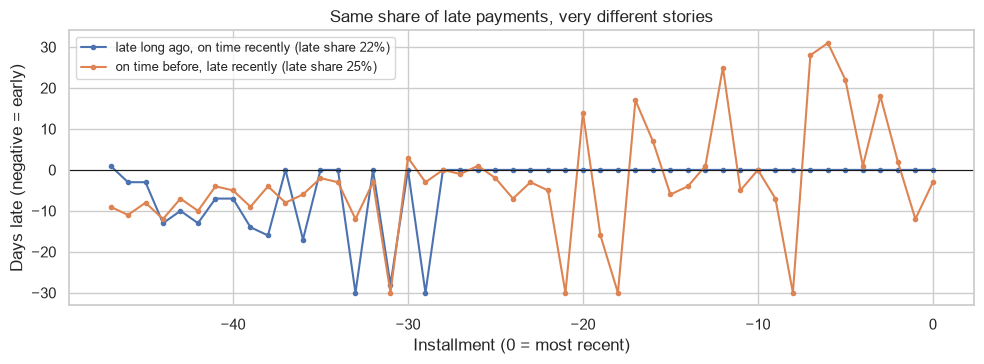

In [3]:
tr = seq[(seq["split"] == "train") & seq["row"].notna()].copy()
tr["row"] = tr["row"].astype(int)
late = X_raw[tr["row"].to_numpy(), :, 0] > 0  # days_late > 0
n = lengths[tr["row"].to_numpy()]
recent_late = np.array([late[i, max(n[i] - 12, 0):n[i]].mean() for i in range(len(tr))])
tr["recent_late"], tr["n"] = recent_late, n
pool = tr[(tr["n"] >= 40) & tr["INST_LATE_SHARE"].between(0.15, 0.30)]
old = pool[pool["recent_late"] == 0].iloc[0]
new = pool[pool["recent_late"] >= 0.5].iloc[0]

fig, ax = plt.subplots(figsize=(10, 3.8))
for r, color, label in [(old, BLUE, "late long ago, on time recently"), (new, ORANGE, "on time before, late recently")]:
    k = int(r["row"])
    days = X_raw[k, : lengths[k], 0] * 30
    ax.plot(np.arange(len(days)) - len(days) + 1, days, marker="o", ms=3, color=color,
            label=f"{label} (late share {r['INST_LATE_SHARE']:.0%})")
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="Installment (0 = most recent)", ylabel="Days late (negative = early)",
       title="Same share of late payments, very different stories")
ax.legend(fontsize=9)
savefig("25_sequence_example")

## 2. Train the GRU out-of-fold
`scripts/train_sequence_scores.py` trains the 5 fold models (architecture in `src/secondlook/sequence_model.py`:
GRU with 32 hidden units → 16-unit dense layer → default logit; Adam, early stopping on validation AUC) and saves one
score per applicant. Set `RETRAIN = True` to retrain.

In [4]:
del X_raw  # free memory before training
RETRAIN = False  # True retrains the 5 GRUs (about 10-15 min); False reuses saved scores
scores_path = PROCESSED_DIR / "sequence_scores.parquet"
if RETRAIN or not scores_path.exists():
    t = time.time()
    run = subprocess.run([sys.executable, str(ROOT / "scripts" / "train_sequence_scores.py")],
                         capture_output=True, text=True, cwd=ROOT)
    print(run.stdout[-1500:])
    if run.returncode != 0:
        raise RuntimeError(run.stderr[-3000:])
training = json.loads((PROCESSED_DIR / "sequence_training.json").read_text())
print(f"Training took {training['minutes']} min. Validation AUC by epoch, per fold:")
for k, h in enumerate(training["valid_auc_per_fold_and_epoch"], 1):
    print(f"  fold {k}: " + "  ".join(f"{a:.3f}" for a in h))

df = df.merge(pd.read_parquet(scores_path)[[ID_COL, "SEQ_SCORE"]], on=ID_COL, how="left")
has = df["SEQ_SCORE"].notna()
ix_tr, ix_va, ix_te = (df.index[(df["split"] == s) & has] for s in ["train", "valid", "test"])
y_te_h = df.loc[ix_te, TARGET_COL].to_numpy()

Training took 9.8 min. Validation AUC by epoch, per fold:
  fold 1: 0.620  0.628  0.632  0.636  0.637  0.641
  fold 2: 0.610  0.621  0.629  0.636  0.640  0.643
  fold 3: 0.616  0.630  0.634  0.637  0.639  0.642
  fold 4: 0.615  0.629  0.636  0.636  0.638  0.640
  fold 5: 0.618  0.635  0.639  0.640  0.644  0.646


### Is the GRU learning something the averages miss?
On applicants with history, compare the GRU's score alone with a LightGBM model given only the six installment
averages from notebook 02. The two see the same raw data, summarised differently.

In [5]:
inst_cols = [c for c in df.columns if c.startswith("INST_")]
d_tr, d_va, d_te = df.loc[ix_tr], df.loc[ix_va], df.loc[ix_te]
avg_model = train_lightgbm(d_tr[inst_cols], d_tr[TARGET_COL], d_va[inst_cols], d_va[TARGET_COL])
p_avg = avg_model.predict_proba(d_te[inst_cols])[:, 1]
cmp = pd.Series({
    "LightGBM on installment averages": roc_auc_score(y_te_h, p_avg),
    "GRU on the installment sequence": roc_auc_score(y_te_h, d_te["SEQ_SCORE"]),
    "Both (average of ranks)": roc_auc_score(y_te_h, pd.Series(p_avg).rank().to_numpy() + d_te["SEQ_SCORE"].rank().to_numpy()),
}, name="test AUC (applicants with history)")
cmp.to_frame().style.format("{:.4f}")

,test AUC (applicants with history)
LightGBM on installment averages,0.5883
GRU on the installment sequence,0.6380
Both (average of ranks),0.6279


## 3. Does the sequence score improve SecondLook?

In [6]:
# the base SecondLook inputs (SEQ_SCORE is now a column of df, so exclude it explicitly)
cols = [c for c in feature_sets(df)["secondlook"] if c != "SEQ_SCORE"]
cols_seq = cols + ["SEQ_SCORE"]
tr_all, va_all, te_all = (df[df["split"] == s] for s in ["train", "valid", "test"])

base = load_bundle("secondlook_lgbm")["model"]  # notebook 03 SecondLook model, same settings
with_seq = train_lightgbm(tr_all[cols_seq], tr_all[TARGET_COL], va_all[cols_seq], va_all[TARGET_COL])
print(f"SecondLook + sequence score: {with_seq.best_iteration_} trees")

y_te = te_all[TARGET_COL].to_numpy()
thin_te = te_all["THIN_FILE"].to_numpy().astype(bool)
has_hist = te_all["SEQ_SCORE"].notna().to_numpy()
p_base = base.predict_proba(te_all[cols])[:, 1]
p_seq = with_seq.predict_proba(te_all[cols_seq])[:, 1]

res = pd.DataFrame({name: {
    "AUC, all": roc_auc_score(y_te, p), "AUC, thin-file": roc_auc_score(y_te[thin_te], p[thin_te]),
    "AUC, has history": roc_auc_score(y_te[has_hist], p[has_hist]),
    **{f"{k} @ {t:.0%}": v for t in [0.04, 0.05] for k, v in approval_at_bad_rate(y_te, p, thin_te, t).items()},
} for name, p in [("SecondLook (notebook 03)", p_base), ("SecondLook + sequence score", p_seq)]}).T
res.columns = [c.replace("thin_approval_rate", "thin-file approved").replace("approval_rate", "approved") for c in res.columns]
res.style.format({c: "{:.4f}" if "AUC" in c else "{:.1%}" for c in res.columns})

SecondLook + sequence score: 954 trees


,"AUC, all","AUC, thin-file","AUC, has history",approved @ 4%,thin-file approved @ 4%,approved @ 5%,thin-file approved @ 5%
SecondLook (notebook 03),0.7756,0.7549,0.7743,74.2%,64.3%,84.1%,78.1%
SecondLook + sequence score,0.7782,0.7602,0.7776,75.0%,66.5%,84.2%,78.3%


In [7]:
ci = bootstrap_auc_diff(y_te, p_base, p_seq,
                        {"all": np.ones(len(y_te), bool), "thin-file": thin_te, "has history": has_hist})
print("AUC gain from adding the sequence score (paired bootstrap, 300 resamples):")
ci.style.format({"mean": "{:+.4f}", "low": "{:+.4f}", "high": "{:+.4f}"})

AUC gain from adding the sequence score (paired bootstrap, 300 resamples):


,mean,low,high,significant
segment,,,,
all,+0.0028,+0.0009,+0.0048,True
thin-file,+0.0052,-0.0013,+0.0119,False
has history,+0.0035,+0.0015,+0.0057,True


SEQ_SCORE is feature #2 of 166 by gain (7.0% of total gain)


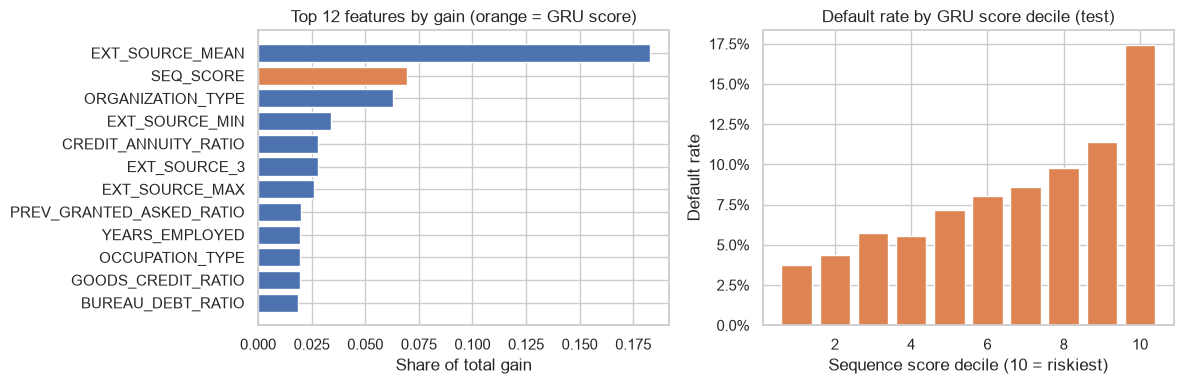

In [8]:
imp = pd.Series(with_seq.booster_.feature_importance("gain"), index=with_seq.booster_.feature_name())
imp = (imp / imp.sum()).sort_values(ascending=False)
rank = int(imp.index.get_loc("SEQ_SCORE")) + 1
print(f"SEQ_SCORE is feature #{rank} of {len(imp)} by gain ({imp['SEQ_SCORE']:.1%} of total gain)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top = imp.head(12).sort_values()
axes[0].barh(top.index, top.values, color=[ORANGE if c == "SEQ_SCORE" else BLUE for c in top.index])
axes[0].set(title="Top 12 features by gain (orange = GRU score)", xlabel="Share of total gain")
q = pd.qcut(te_all.loc[has_hist, "SEQ_SCORE"], 10, labels=False)
rate = te_all.loc[has_hist].groupby(q)[TARGET_COL].mean()
axes[1].bar(rate.index + 1, rate.values, color=ORANGE)
axes[1].set(title="Default rate by GRU score decile (test)", xlabel="Sequence score decile (10 = riskiest)", ylabel="Default rate")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
savefig("26_sequence_score")

In [9]:
save_bundle("secondlook_seq_lgbm", with_seq, None, cols_seq,
            {c: list(df[c].cat.categories) for c in cols if isinstance(df[c].dtype, pd.CategoricalDtype)},
            {"test_metrics": res.loc["SecondLook + sequence score"].to_dict(),
             "auc_gain_bootstrap": ci.reset_index().to_dict(orient="records"),
             "note": "Uncalibrated; SEQ_SCORE comes from data/processed/sequence_scores.parquet (out-of-fold for train)."})
print("Saved models/secondlook_seq_lgbm.joblib")

Saved models/secondlook_seq_lgbm.joblib


## Takeaways

All numbers are on the untouched test split.

1. **Order carries information the averages throw away.** On applicants with repayment history, the GRU's sequence score alone reaches AUC 0.638, versus 0.588 for a LightGBM model given only the six installment averages from notebook 02. Same raw data, better representation.
2. **It improves SecondLook, and the gain is real.** Adding the one sequence score lifts AUC from 0.7756 to 0.7782 (+0.0028; bootstrap 95% interval +0.0009 to +0.0048) and by +0.0035 for applicants with history (interval excludes zero). It becomes the #2 feature of 166 by gain (7.0%).
3. **Thin-file applicants benefit too, though less certainly.** Thin-file AUC rises from 0.7549 to 0.7602 (+0.0052, interval just includes zero), and 2.2 points more thin-file applicants are approved at a 4% default rate (64.3% to 66.5%). This fits the EDA: 95% of thin-file applicants have Home Credit repayment history even though they have no bureau record.
4. **Risk rises steadily across GRU score deciles**, from 3.7% defaults in the lowest tenth to 17.5% in the highest.
5. **Engineering lessons.** (a) Out-of-fold training was essential: in-sample GRU scores would leak each applicant's outcome into LightGBM. (b) On macOS, PyTorch and LightGBM crash in the same process (clashing OpenMP runtimes), so the GRU trains in its own script and the tests run it in a separate process.
6. **Room to improve.** Validation AUC was still rising at epoch 6 in every fold, so longer training (or the POS and credit-card monthly sequences) may add more. Naively averaging the GRU and the averages model (0.628) does worse than letting LightGBM combine them, so the stacked model is the right way to use it.